In [2]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

In [3]:
color_map = {
    "NMPs": "orange",
    "NeuralTube": "skyblue",
    "Somite": "green",
    "Endoderm": "yellow",
    "Endothelial": "blue",
    "PGCLC": "purple",
    "MP": "pink",
    "NMSTD": "cyan",
    "NMSD": "gold",
    "NMS": "brown",
    "NS": "lightcoral",
    "?": "red"
}

In [4]:
def plot_differentiation_tree(
    diff_T,
    birth_rates=None,
    death_rates=None,
    transition_probabilities=None,
    show_labels=True,
    figsize=(6, 5),
):
    """
    Plot differentiation tree with optional birth/death rates and transition probabilities.
    
    Nodes: cell types (showing τ, b, d)
    Edges: differentiation paths (showing transition probabilities)
    """
    diff_T = diff_T.copy()  # avoid modifying original graph
    plt.figure(figsize=figsize)
    pos = nx.nx_agraph.graphviz_layout(diff_T, prog="dot")

    # Node labels
    node_labels = {}
    for n in diff_T.nodes:
        label = f"{n}"
        if diff_T.nodes[n].get("diff_time") is not None:
            label += f"\nτ={diff_T.nodes[n]['diff_time']:.2f}"
        if diff_T.nodes[n].get("diff_times") is not None:
            times_str = ", ".join(f"{t:.2f}" for t in diff_T.nodes[n]["diff_times"] if t is not None)
            if times_str:
                label += f"\nτs=[{times_str}]"
        if birth_rates is not None:
            label += f"\n$\\mu_b$={birth_rates.get(n, 0):.2f}"
        if death_rates is not None:
            label += f"\n$\\mu_d$={death_rates.get(n, 0):.2f}"
        node_labels[n] = label

    # Edge labels (transition probabilities)
    edge_labels = {}
    if transition_probabilities is not None:
        for u, v in diff_T.edges:
            prob = transition_probabilities.loc[u, v] if (
                u in transition_probabilities.index and v in transition_probabilities.columns
            ) else 0.0
            edge_labels[(u, v)] = f"{prob:.3f}"

    # Node colors
    node_colors = [color_map.get(n, "lightblue") if color_map else "lightblue" for n in diff_T.nodes()]

    # Draw tree
    nx.draw(
        diff_T,
        pos,
        with_labels=False,
        node_size=900,
        node_color=node_colors,
        arrows=True
    )

    # Draw node labels (smaller font)
    if show_labels:
        nx.draw_networkx_labels(
            diff_T,
            pos,
            labels=node_labels,
            font_size=8,       # smaller font
            font_color="black"
        )

        # Draw edge labels (red, smaller)
        if transition_probabilities is not None:
            nx.draw_networkx_edge_labels(
                diff_T,
                pos,
                edge_labels=edge_labels,
                font_size=7,
                font_color="red"
            )

    plt.axis("off")
    plt.tight_layout()
    plt.show()



In [5]:
states = [
    "MP",          # 0
    "NMSTD",       # 1
    "NMSD",        # 2
    "NMS",         # 3
    "NS",          # 4
    "PGCLC",       # 5
    "Endothelial", # 6
    "Endoderm",    # 7
    "NMPs",        # 8
    "Somite",      # 9
    "NeuralTube",  # 10
]

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_57110/98870812.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


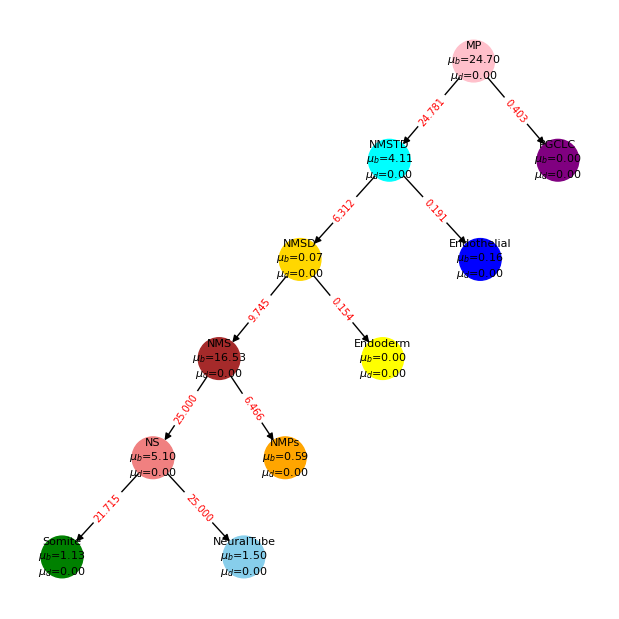

In [6]:
import pandas as pd
import networkx as nx

birth_rates = {
    "MP": 24.7042,
    "NMSTD": 4.1086,
    "NMSD": 0.0716978,
    "NMS": 16.5337,
    "NS": 5.10353,
    "PGCLC": 0.000411296,
    "Endothelial": 0.159831,
    "Endoderm": 2.38705e-19,
    "NMPs": 0.588271,
    "Somite": 1.12932,
    "NeuralTube": 1.49818,
}

death_rates = {s: 0.0 for s in states}

transition_probabilities = pd.DataFrame(
    0.0,
    index=states,
    columns=states,
)

transition_probabilities.loc["MP", "NMSTD"] = 24.781
transition_probabilities.loc["MP", "PGCLC"] = 0.403167

transition_probabilities.loc["NMSTD", "NMSD"] = 6.3121
transition_probabilities.loc["NMSTD", "Endothelial"] = 0.190998

transition_probabilities.loc["NMSD", "NMS"] = 9.74486
transition_probabilities.loc["NMSD", "Endoderm"] = 0.154177

transition_probabilities.loc["NMS", "NS"] = 25.0
transition_probabilities.loc["NMS", "NMPs"] = 6.46594

transition_probabilities.loc["NS", "Somite"] = 21.7152
transition_probabilities.loc["NS", "NeuralTube"] = 25.0

diff_T = nx.DiGraph()
diff_T.add_edges_from([
    ("MP", "NMSTD"),
    ("MP", "PGCLC"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
])

plot_differentiation_tree(
    diff_T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=transition_probabilities,
    figsize=(6, 6),
)

In [7]:
birth_rates = {
    "MP": 23.9759,
    "NMSTD": 4.09732,
    "NMSD": 0.130886,
    "NMS": 17.3294,
    "NS": 5.03826,
    "PGCLC": 0.000388197,
    "Endothelial": 0.142379,
    "Endoderm": 2.60315e-19,
    "NMPs": 0.635451,
    "Somite": 1.13431,
    "NeuralTube": 1.51277,
}

death_rates = {
    "MP": 0.000559402,
    "NMSTD": 0.00330822,
    "NMSD": 0.0018928,
    "NMS": 0.0349011,
    "NS": 0.108698,
    "PGCLC": 0.000281347,
    "Endothelial": 0.128546,
    "Endoderm": 2.60045e-21,
    "NMPs": 0.390091,
    "Somite": 0.250429,
    "NeuralTube": 0.24183,
}

transition_probabilities = pd.DataFrame(
    0.0,
    index=states,
    columns=states,
)

transition_probabilities.loc["MP", "NMSTD"] = 24.777
transition_probabilities.loc["MP", "PGCLC"] = 0.407213

transition_probabilities.loc["NMSTD", "NMSD"] = 6.34674
transition_probabilities.loc["NMSTD", "Endothelial"] = 0.194776

transition_probabilities.loc["NMSD", "NMS"] = 11.2776
transition_probabilities.loc["NMSD", "Endoderm"] = 0.154118

transition_probabilities.loc["NMS", "NS"] = 24.9647
transition_probabilities.loc["NMS", "NMPs"] = 6.78439

transition_probabilities.loc["NS", "Somite"] = 22.3779
transition_probabilities.loc["NS", "NeuralTube"] = 24.9602

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_57110/98870812.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


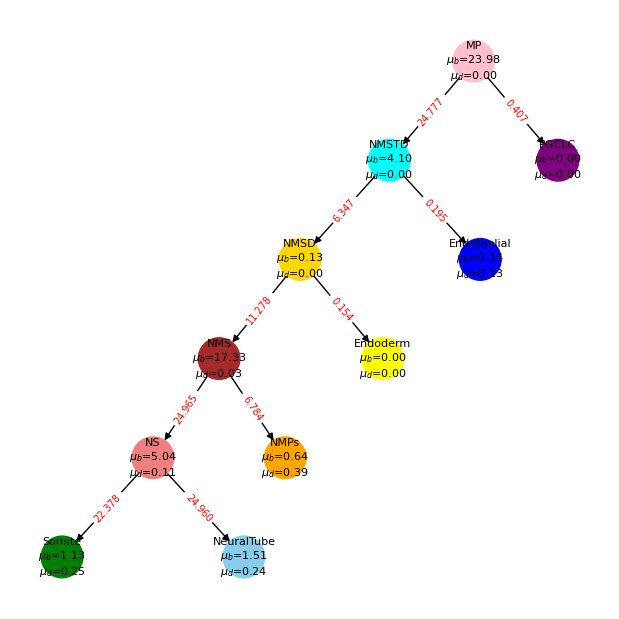

In [8]:
diff_T = nx.DiGraph()
diff_T.add_edges_from([
    ("MP", "NMSTD"),
    ("MP", "PGCLC"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
])

plot_differentiation_tree(
    diff_T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=transition_probabilities,
    figsize=(6, 6),
)

In [9]:
birth_rates = {
    "MP": 21.3237,
    "NMSTD": 6.71506,
    "NMSD": 0.850367,
    "NMS": 8.67734,
    "NS": 5.55869,
    "PGCLC": 0.000381738,
    "Endothelial": 0.28783,
    "Endoderm": 9.85104e-20,
    "NMPs": 1.48115,
    "Somite": 2.22852,
    "NeuralTube": 2.45521,
}

death_rates = {
    "MP": 0.000269655,
    "NMSTD": 0.000696743,
    "NMSD": 0.00206865,
    "NMS": 0.0359079,
    "NS": 0.0300526,
    "PGCLC": 0.000321475,
    "Endothelial": 0.0301534,
    "Endoderm": 6.05027e-38,
    "NMPs": 0.00280341,
    "Somite": 0.000926124,
    "NeuralTube": 9.53649e-19,
}

In [10]:
transition_probabilities = pd.DataFrame(
    0.0,
    index=states,
    columns=states,
)

transition_probabilities.loc["MP", "NMSTD"] = 24.7176
transition_probabilities.loc["MP", "PGCLC"] = 0.767406

transition_probabilities.loc["NMSTD", "NMSD"] = 9.23506
transition_probabilities.loc["NMSTD", "Endothelial"] = 0.3916

transition_probabilities.loc["NMSD", "NMS"] = 2.29616
transition_probabilities.loc["NMSD", "Endoderm"] = 0.0397901

transition_probabilities.loc["NMS", "NS"] = 24.9337
transition_probabilities.loc["NMS", "NMPs"] = 3.69567

transition_probabilities.loc["NS", "Somite"] = 9.58776
transition_probabilities.loc["NS", "NeuralTube"] = 24.9816

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_57110/98870812.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


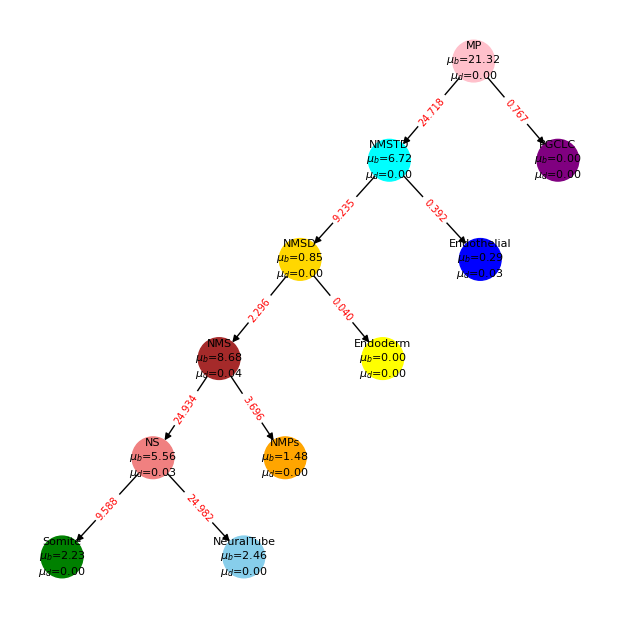

In [11]:
diff_T = nx.DiGraph()
diff_T.add_edges_from([
    ("MP", "NMSTD"),
    ("MP", "PGCLC"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
])

plot_differentiation_tree(
    diff_T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=transition_probabilities,
    figsize=(6, 6),
)

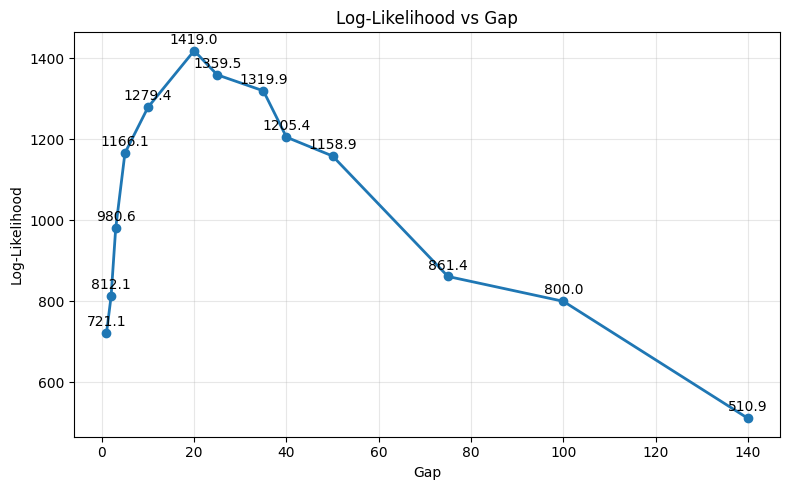

In [3]:
import matplotlib.pyplot as plt

gaps = [1, 2, 3, 5, 10, 20, 25, 35, 40, 50, 75, 100, 140]

log_likelihoods = [
    721.073157813475518,
    812.113545096103053,
    980.605571102539557,
    1166.139566163930112,
    1279.354109880308215,
    1418.992138690021193,
    1359.458355924292391,
    1319.866963629449174,
    1205.443759969694838,
    1158.877160625030456,
    861.368170642539894,
    799.991662830548535,
    510.932628119256890,
]

plt.figure(figsize=(8, 5))

plt.plot(gaps, log_likelihoods, marker="o", linewidth=2)

for x, y in zip(gaps, log_likelihoods):
    plt.annotate(
        f"{y:.1f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 5),
        ha="center"
    )

plt.xlabel("Gap")
plt.ylabel("Log-Likelihood")
plt.title("Log-Likelihood vs Gap")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()